# ML6 - Customer Segmentation

In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

In [2]:
train = pd.read_csv("../data/processed/train.csv")

customer_ids = train["Customer ID"].unique()
product_codes = train["StockCode"].unique()

customer_map = {customer: i for i, customer in enumerate(customer_ids)}
product_map = {product: j for j, product in enumerate(product_codes)}

rows = train["Customer ID"].map(customer_map)
cols = train["StockCode"].map(product_map)
values = np.log1p(train["Quantity"])

A = sp.csr_matrix(
    (values, (rows, cols)),
    shape=(len(customer_map), len(product_map))
)

svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

customer_factors = svd.fit_transform(A)

print(customer_factors.shape)

(5474, 100)


## Customer Clustering


In [3]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(customer_factors)

print("Cluster sizes:")

unique, counts = np.unique(clusters, return_counts=True)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} customers")

Cluster sizes:
Cluster 0: 5443 customers
Cluster 1: 1 customers
Cluster 2: 1 customers
Cluster 3: 29 customers


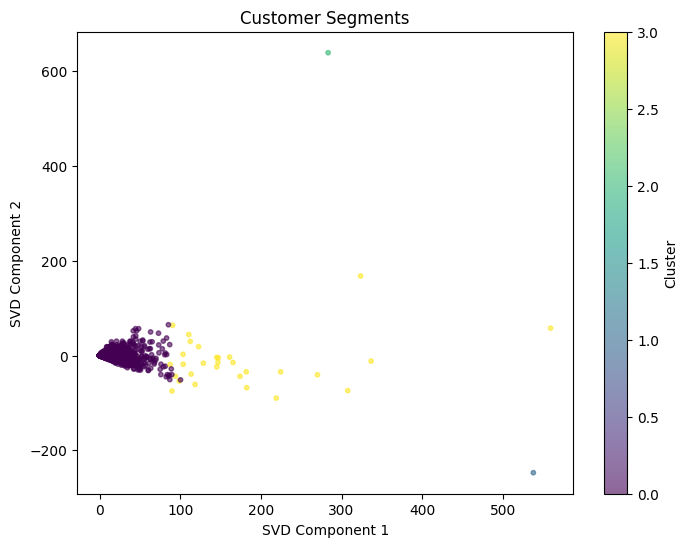

In [4]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    customer_factors[:, 0],
    customer_factors[:, 1],
    c=clusters,
    s=10,
    alpha=0.6
)

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Customer Segments")
plt.colorbar(scatter, label="Cluster")
plt.show()

## Normalize Customer Representations

In [5]:
from sklearn.preprocessing import normalize

customer_factors_normalized = normalize(customer_factors)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(customer_factors_normalized)

unique, counts = np.unique(clusters, return_counts=True)

print("Cluster sizes:")

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count} customers")

Cluster sizes:
Cluster 0: 831 customers
Cluster 1: 2375 customers
Cluster 2: 693 customers
Cluster 3: 1575 customers


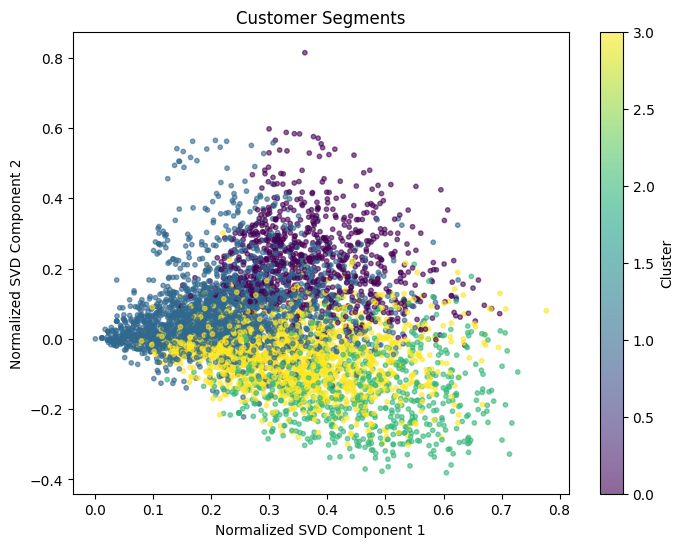

In [6]:
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    customer_factors_normalized[:, 0],
    customer_factors_normalized[:, 1],
    c=clusters,
    s=10,
    alpha=0.6
)

plt.xlabel("Normalized SVD Component 1")
plt.ylabel("Normalized SVD Component 2")
plt.title("Customer Segments")
plt.colorbar(scatter, label="Cluster")

from pathlib import Path

Path("../figures").mkdir(parents=True, exist_ok=True)
plt.savefig(
    "../figures/customer_segments.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Describe Customer Segments


In [7]:
customer_cluster_df = pd.DataFrame({
    "Customer ID": customer_ids,
    "Cluster": clusters
})


In [8]:
train_with_clusters = train.merge(
    customer_cluster_df,
    on="Customer ID",
    how="left"
)

In [9]:
for cluster in sorted(train_with_clusters["Cluster"].unique()):
    cluster_data = train_with_clusters[
        train_with_clusters["Cluster"] == cluster
    ]

    print(f"\n--- Cluster {cluster} ---")

    print("\nTop products:")
    top_products = (
        cluster_data.groupby(["StockCode", "Description"])["Quantity"]
        .sum()
        .sort_values(ascending=False)
        .head(5)
    )
    print(top_products)

    print("\nTop countries:")
    top_countries = (
        cluster_data["Country"]
        .value_counts()
        .head(5)
    )
    print(top_countries)


--- Cluster 0 ---

Top products:
StockCode  Description                        
85123A     WHITE HANGING HEART T-LIGHT HOLDER     59778
84879      ASSORTED COLOUR BIRD ORNAMENT          13570
22469      HEART OF WICKER SMALL                  11868
84755      COLOUR GLASS T-LIGHT HOLDER HANGING    10046
21733      RED HANGING HEART T-LIGHT HOLDER        9771
Name: Quantity, dtype: int64

Top countries:
Country
United Kingdom    129249
Cyprus               585
France               401
Spain                357
Singapore            300
Name: count, dtype: int64

--- Cluster 1 ---

Top products:
StockCode  Description                       
23166      MEDIUM CERAMIC TOP STORAGE JAR        75170
84879      ASSORTED COLOUR BIRD ORNAMENT         29770
37410      BLACK AND WHITE PAISLEY FLOWER MUG    25654
16014      SMALL CHINESE STYLE SCISSOR           24760
21982      PACK OF 12 SUKI TISSUES               22560
Name: Quantity, dtype: int64

Top countries:
Country
United Kingdom    169654
Ge

## Segment Names

KMeans cluster numbers are arbitrary and can permute between runs when the input data
changes, so each segment is named from the single highest-volume product in that cluster
rather than from its cluster number. The mapping is asserted to be one-to-one below, which
fails loudly if a cluster's character changes rather than silently mislabelling it.


In [10]:
segment_anchors = {
    "23166": "Home & Utility",        # MEDIUM CERAMIC TOP STORAGE JAR
    "84077": "Novelty & Party",       # WORLD WAR 2 GLIDERS ASSTD DESIGNS
    "85099B": "Bags & Storage",       # JUMBO BAG RED RETROSPOT
    "85123A": "Decorative Homeware",  # WHITE HANGING HEART T-LIGHT HOLDER
}

top_product = (
    train_with_clusters.groupby(["Cluster", "StockCode"])["Quantity"]
    .sum()
    .groupby(level=0)
    .idxmax()
    .apply(lambda key: str(key[1]))
)

cluster_names = {
    cluster: segment_anchors.get(product, f"UNNAMED ({product})")
    for cluster, product in top_product.items()
}

assert sorted(cluster_names.values()) == sorted(segment_anchors.values()), (
    f"cluster to segment mapping is not one-to-one: {cluster_names}"
)

sizes = customer_cluster_df["Cluster"].value_counts().sort_index()
ordered = sorted(cluster_names)

segment_summary = pd.DataFrame({
    "Cluster": ordered,
    "Top Product": [top_product[c] for c in ordered],
    "Segment Name": [cluster_names[c] for c in ordered],
    "Customers": [int(sizes[c]) for c in ordered],
})

segment_summary


,Cluster,Top Product,Segment Name,Customers
0,0,85123A,Decorative Homeware,831
1,1,23166,Home & Utility,2375
2,2,85099B,Bags & Storage,693
3,3,84077,Novelty & Party,1575
